# Proyecto 04: El Dominio de Fourier: Filtrado en la Frecuencia

## 0. Código y Funciones Auxiliares

In [80]:
# Import de librerías para la realización del proyecto

from pathlib import Path
from typing import Callable

import cv2
import numpy as np
import matplotlib.pyplot as plt

### 0.1 Carga de Imágenes

In [77]:
def load_images_dataset():
    """
    Función para cargar/leer las imágenes del dataset del proyecto. 
    Se cargan usando OpenCV y convertidas al formato a escala de grises.

    Devuelve tres listas, una con las imágenes cargadas, una 
    con los nombres de las imágenes y otra con el dominio 
    de frecuencias por FFT.
    """

    base_path = Path("./dataset")
    images = []
    filenames =  []
    ftts = []
    for path in base_path.iterdir():
        image = cv2.imread(path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        frequencies = np.fft.fft2(image)
        frequencies = np.fft.fftshift(frequencies)
        images.append(image)
        filenames.append(path.name[-5])
        ftts.append(frequencies)
    return images, filenames, ftts

In [78]:
Path("./results").mkdir(exist_ok=True)
images, filenames, ffts = load_images_dataset()

### 0.4 Visualizar Transformaciones

In [81]:
def save_plot(
        create_plot: Callable[[np.ndarray, str], tuple[plt.Figure, str | None]]
    ) -> Callable:
    """
    Función para guardar un plot diseñado o 
    creado. Se espera que la función decorada 
    devuelva el objeto Figure y el nombre de 
    la figura.

    Devuelve el plot creado.
    """

    def saver(image: np.ndarray, *args, **kwargs) -> plt.Figure:
        fig, fig_name = create_plot(image, *args, **kwargs)
        if fig_name: fig.savefig(f"./results/{fig_name}.jpg", dpi=300, bbox_inches="tight")
        return fig
    
    return saver

In [101]:
@save_plot
def initial_description(
        image: np.ndarray, 
        fft_image: np.ndarray, 
        filename: str
    ) -> tuple[plt.Figure, str]:
    """
    Función para graficar la imagen inicial 
    y su dominio de frecuencias. 
    Devuelve el plot generado.
    """

    fig, axes = plt.subplots(
        ncols = 2,
        subplot_kw = {
            "yticks": [],
            "xticks": [],
        },
        figsize = (8, 4),
    )
    axes: list[plt.Axes]

    axes[0].imshow(image, "gray")
    axes[0].set_title("Imagen Original")
    
    axes[1].imshow(np.log1p(np.abs(fft_image)), "gray")
    axes[1].set_title("Dominio de Frecuencias")
    
    fig.suptitle(f"Visualización Inicial de la Imagen {filename}")

    return fig, f"img_{filename}_initial"

## Imagen 1

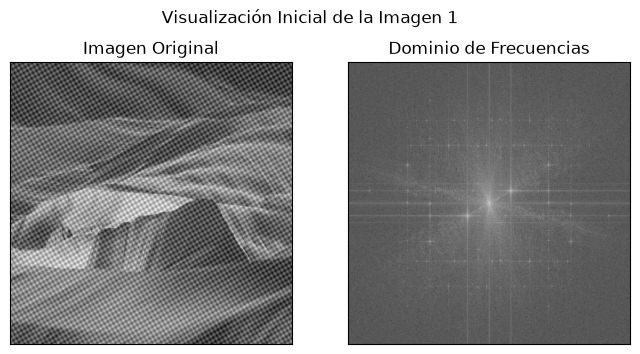

In [102]:
idx = 0
img_1 = images[idx]
name_1 = filenames[idx]
fft_1 = ffts[idx]

initial_description(img_1, fft_1, name_1);

## Imagen 2

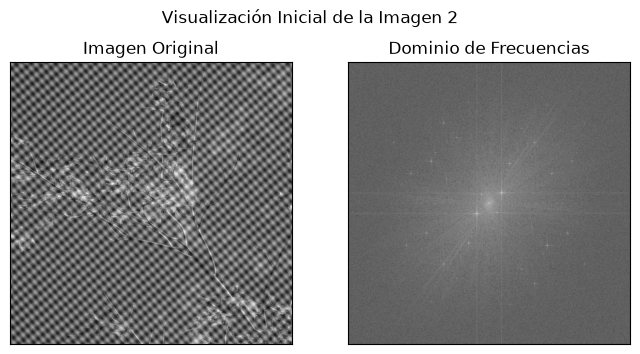

In [103]:
idx = 1
img_2 = images[idx]
name_2 = filenames[idx]
fft_2 = ffts[idx]

initial_description(img_2, fft_2, name_2);

## Imagen 3

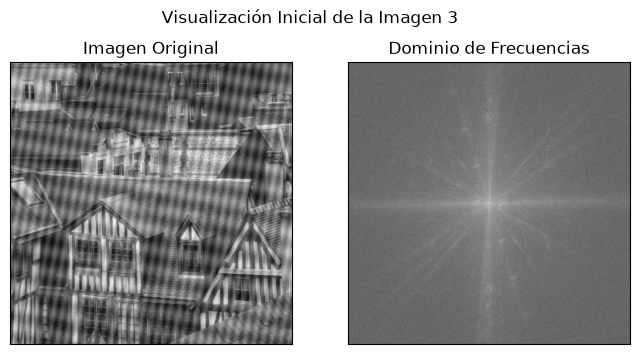

In [104]:
idx = 2
img_3 = images[idx]
name_3 = filenames[idx]
fft_3 = ffts[idx]

initial_description(img_3, fft_3, name_3);

## Imagen 4

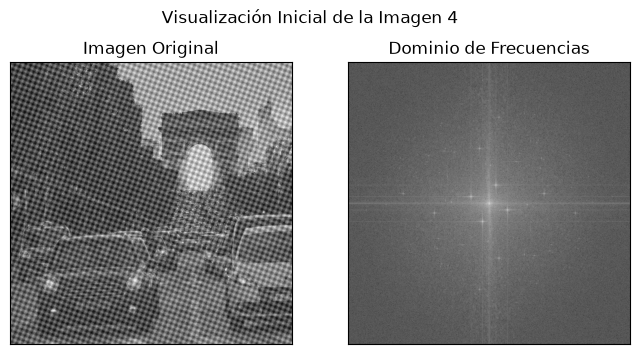

In [105]:
idx = 3
img_4 = images[idx]
name_4 = filenames[idx]
fft_4 = ffts[idx]

initial_description(img_4, fft_4, name_4);

## Imagen 5

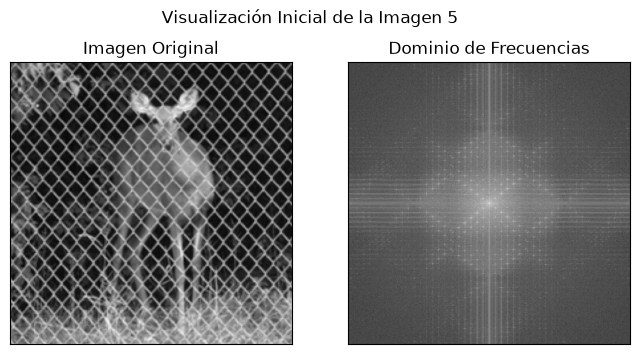

In [106]:
idx = 4
img_5 = images[idx]
name_5 = filenames[idx]
fft_5 = ffts[idx]

initial_description(img_5, fft_5, name_5);